## 1. Environment Setup & Dependency Installation


In [ ]:
# Install required specialized packages in Colab
!pip install -q lightgbm xgboost shap ipywidgets

import os
import sys
import requests
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modeling & metrics
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    brier_score_loss, roc_curve, precision_recall_curve
)

# Gradient boosting
import lightgbm as lgb
import xgboost as xgb

# Deep tabular learning
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Explainability & widgets
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False

import ipywidgets as widgets
from IPython.display import display, clear_output

# Global plot styling
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Reproducibility seeds
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[OK] CardioSense AI Environment Configured. Compute device: {device}")


[OK] CardioSense AI Environment Configured. Compute device: cuda


In [ ]:
def get_nhanes_dataset():
    local_candidates = [
        'nhanes_cvd_2015_2018.csv',
        'data/processed/nhanes_cvd_2015_2018.csv',
        '../data/processed/nhanes_cvd_2015_2018.csv'
    ]
    for p in local_candidates:
        if os.path.exists(p):
            print(f"[FOUND] Local dataset at '{p}'. Loading directly...")
            return pd.read_csv(p)

    print("[DOWNLOADING] Local CSV not found. Initiating automated CDC NHANES download pipeline...")
    raw_dir = "raw_nhanes_colab"
    os.makedirs(raw_dir, exist_ok=True)

    base_2015 = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2015/DataFiles/"
    base_2017 = "https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2017/DataFiles/"

    modules = ["DEMO", "BMX", "BPX", "TCHOL", "HDL", "TRIGLY", "GLU", "GHB", "HSCRP", "MCQ"]
    targets = [(base_2015, "_I"), (base_2017, "_J")]

    for base_url, suffix in targets:
        for mod in modules:
            fname = f"{mod}{suffix}.XPT"
            dest = os.path.join(raw_dir, fname)
            if not os.path.exists(dest):
                url = base_url + fname
                print(f"  Downloading CDC module: {fname}...")
                resp = requests.get(url, timeout=60)
                resp.raise_for_status()
                with open(dest, 'wb') as f:
                    f.write(resp.content)

    print("[OK] All CDC XPT files downloaded. Merging cycles...")
    def merge_cycle(suffix, cycle_name):
        demo = pd.read_sas(os.path.join(raw_dir, f"DEMO{suffix}.XPT"))[["SEQN", "RIDAGEYR", "RIAGENDR"]]
        mods = [
            (f"BMX{suffix}.XPT", ["BMXBMI", "BMXWAIST"]),
            (f"BPX{suffix}.XPT", ["BPXSY1", "BPXSY2", "BPXSY3", "BPXDI1", "BPXDI2", "BPXDI3", "BPXPLS"]),
            (f"TCHOL{suffix}.XPT", ["LBXTC"]),
            (f"HDL{suffix}.XPT", ["LBDHDD"]),
            (f"TRIGLY{suffix}.XPT", ["LBXTR"]),
            (f"GLU{suffix}.XPT", ["LBXGLU"]),
            (f"GHB{suffix}.XPT", ["LBXGH"]),
            (f"HSCRP{suffix}.XPT", ["LBXHSCRP"]),
            (f"MCQ{suffix}.XPT", ["MCQ160C", "MCQ160D", "MCQ160E", "MCQ160F"])
        ]
        df_c = demo.copy()
        for f, cols in mods:
            path = os.path.join(raw_dir, f)
            if os.path.exists(path):
                m_df = pd.read_sas(path)
                keep = ["SEQN"] + [c for c in cols if c in m_df.columns]
                df_c = pd.merge(df_c, m_df[keep], on="SEQN", how="left")
        df_c["cycle"] = cycle_name
        return df_c

    df15 = merge_cycle("_I", "2015-2016")
    df17 = merge_cycle("_J", "2017-2018")
    full = pd.concat([df15, df17], ignore_index=True)

    # Blood pressure averaging across readings
    sys_cols = [c for c in ["BPXSY1", "BPXSY2", "BPXSY3"] if c in full.columns]
    dia_cols = [c for c in ["BPXDI1", "BPXDI2", "BPXDI3"] if c in full.columns]
    full["sys_bp"] = full[sys_cols].mean(axis=1, skipna=True)
    full["dia_bp"] = full[dia_cols].mean(axis=1, skipna=True)

    # Target CVD construction (coronary heart disease, angina, heart attack, stroke)
    mcq_cols = ["MCQ160C", "MCQ160D", "MCQ160E", "MCQ160F"]
    for c in mcq_cols:
        full[c] = full[c].replace({7: np.nan, 9: np.nan, 77: np.nan, 99: np.nan})
    mcq_sub = full[mcq_cols]
    has_yes = (mcq_sub == 1.0).any(axis=1)
    all_no = (~has_yes) & ((mcq_sub == 2.0).sum(axis=1) > 0) & ((mcq_sub == 1.0).sum(axis=1) == 0)

    target = pd.Series(np.nan, index=full.index)
    target[has_yes] = 1.0
    target[all_no] = 0.0
    full["target_cvd"] = target

    col_map = {
        "SEQN": "seqn", "cycle": "cycle", "RIDAGEYR": "age", "RIAGENDR": "gender",
        "BMXBMI": "bmi", "BMXWAIST": "waist_circumference", "sys_bp": "sys_bp",
        "dia_bp": "dia_bp", "BPXPLS": "pulse_rate", "LBXTC": "tot_chol",
        "LBDHDD": "hdl_chol", "LBXTR": "triglycerides", "LBXGLU": "glucose",
        "LBXGH": "hba1c", "LBXHSCRP": "hs_crp", "target_cvd": "target_cvd"
    }
    df_clean = full.rename(columns=col_map)[[c for c in col_map.values() if c in full.columns]]
    df_clean.to_csv("nhanes_cvd_2015_2018.csv", index=False)
    print("[SAVED] Processed dataset to 'nhanes_cvd_2015_2018.csv'.")
    return df_clean

raw_df = get_nhanes_dataset()
print(f"Total surveyed rows: {len(raw_df)}")

# Filter modeling cohort: Adults (age >= 20) with valid CVD survey responses
cohort_df = raw_df[(raw_df["age"] >= 20) & (raw_df["target_cvd"].notna())].copy()
cohort_df["target_cvd"] = cohort_df["target_cvd"].astype(int)

n_total = len(cohort_df)
n_pos = int(cohort_df["target_cvd"].sum())
n_neg = n_total - n_pos
prev = n_pos / n_total

print("\n" + "="*50)
print("--- ADULT MODELING COHORT SUMMARY ---")
print("="*50)
print(f"Total Adult Participants (Age >= 20): {n_total:,}")
print(f"CVD Positive Diagnoses (Class 1):    {n_pos:,} ({prev*100:.2f}%)")
print(f"CVD Negative Diagnoses (Class 0):    {n_neg:,} ({(1-prev)*100:.2f}%)")
print(f"Class Imbalance Ratio:                {n_neg/n_pos:.2f} : 1")
print("="*50)


[FOUND] Local dataset at 'nhanes_cvd_2015_2018.csv'. Loading directly...
Total surveyed rows: 19225

--- ADULT MODELING COHORT SUMMARY ---
Total Adult Participants (Age >= 20): 11,286
CVD Positive Diagnoses (Class 1):    1,198 (10.61%)
CVD Negative Diagnoses (Class 0):    10,088 (89.39%)
Class Imbalance Ratio:                8.42 : 1


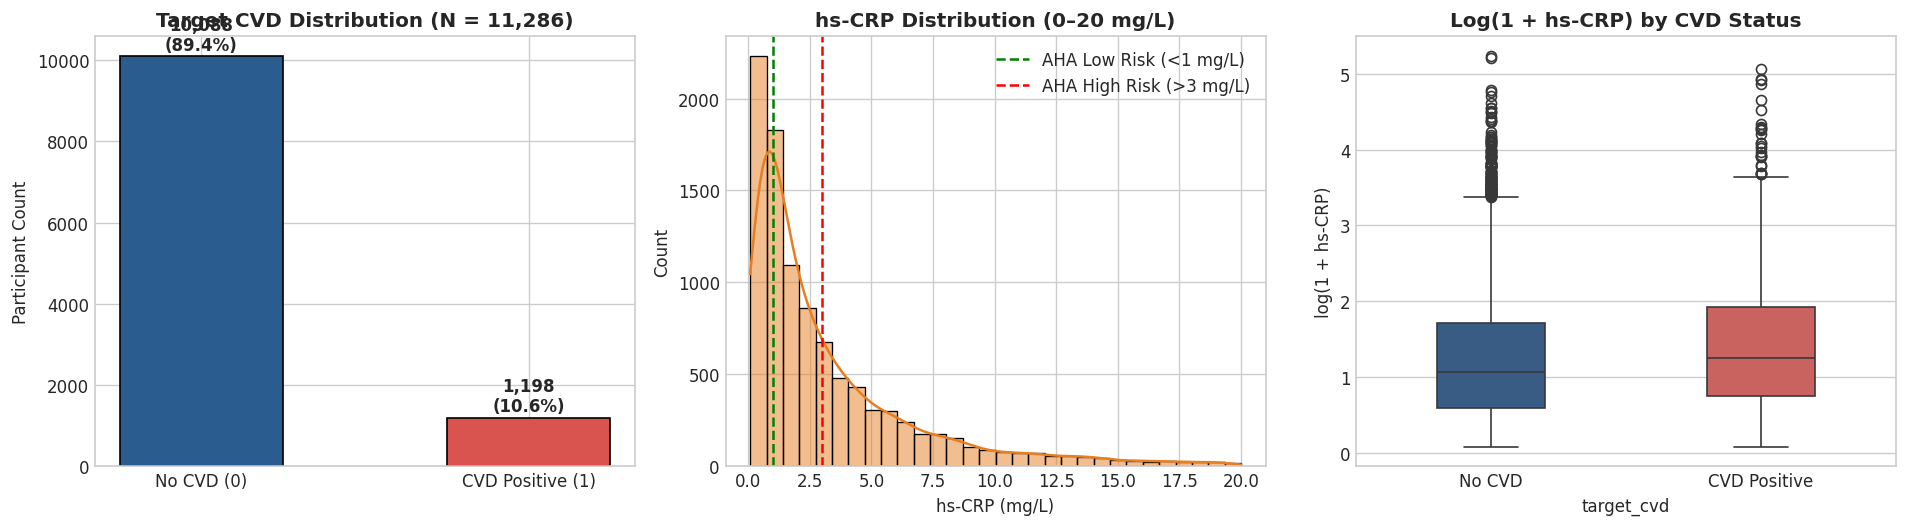

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Class prevalence
axes[0].bar(['No CVD (0)', 'CVD Positive (1)'], [n_neg, n_pos], color=['#2b5c8f', '#d9534f'], width=0.5, edgecolor='black')
axes[0].set_title(f"Target CVD Distribution (N = {n_total:,})", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Participant Count")
for i, v in enumerate([n_neg, n_pos]):
    axes[0].text(i, v + 150, f"{v:,}\n({v/n_total*100:.1f}%)", ha='center', fontweight='bold')

# 2. hs-CRP Distribution (Showing strong right-skewness)
crp_vals = cohort_df['hs_crp'].dropna()
sns.histplot(crp_vals[crp_vals <= 20], bins=30, kde=True, color='#e67e22', ax=axes[1])
axes[1].axvline(1.0, color='green', linestyle='--', label='AHA Low Risk (<1 mg/L)')
axes[1].axvline(3.0, color='red', linestyle='--', label='AHA High Risk (>3 mg/L)')
axes[1].set_title("hs-CRP Distribution (0–20 mg/L)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("hs-CRP (mg/L)")
axes[1].legend(loc='upper right')

# 3. hs-CRP vs CVD Status (Boxplot on log scale)
cohort_plot = cohort_df.copy()
cohort_plot['log_hs_crp'] = np.log1p(cohort_plot['hs_crp'])
sns.boxplot(x='target_cvd', y='log_hs_crp', data=cohort_plot, palette=['#2b5c8f', '#d9534f'], ax=axes[2], width=0.4)
axes[2].set_xticklabels(['No CVD', 'CVD Positive'])
axes[2].set_title("Log(1 + hs-CRP) by CVD Status", fontsize=12, fontweight='bold')
axes[2].set_ylabel("log(1 + hs-CRP)")

plt.tight_layout()
plt.show()


In [ ]:
# 1. Stratified 70 / 15 / 15 Split
train_df, temp_df = train_test_split(
    cohort_df, test_size=0.30, random_state=SEED, stratify=cohort_df["target_cvd"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["target_cvd"]
)

print(f"[TRAIN] Cohort:      {len(train_df):,} samples | Positive CVD: {train_df['target_cvd'].sum():,} ({train_df['target_cvd'].mean()*100:.2f}%)")
print(f"[VALIDATION] Cohort: {len(val_df):,} samples | Positive CVD: {val_df['target_cvd'].sum():,} ({val_df['target_cvd'].mean()*100:.2f}%)")
print(f"[TEST] Cohort:       {len(test_df):,} samples | Positive CVD: {test_df['target_cvd'].sum():,} ({test_df['target_cvd'].mean()*100:.2f}%)")

# 2. Feature Engineering Pipeline (Row-wise, deterministic clinical formulas)
def engineer_clinical_features(data):
    d = data.copy()
    # Hemodynamics
    d["pulse_pressure"] = d["sys_bp"] - d["dia_bp"]
    d["mean_arterial_pressure"] = d["dia_bp"] + (d["sys_bp"] - d["dia_bp"]) / 3.0

    # Atherogenic lipid ratios
    d["chol_hdl_ratio"] = d["tot_chol"] / (d["hdl_chol"] + 1e-5)
    d["non_hdl_chol"] = d["tot_chol"] - d["hdl_chol"]

    # Inflammatory biomarker transformations
    crp_safe = np.maximum(d["hs_crp"].fillna(1.5), 0)
    d["log_hs_crp"] = np.log1p(crp_safe)
    d["crp_high_risk"] = (d["hs_crp"] > 3.0).astype(float)

    # Cardiometabolic interaction terms
    d["age_bmi_risk"] = (d["age"] / 10.0) * (d["bmi"] / 10.0)
    d["cardio_inflammatory_index"] = (d["sys_bp"] / 120.0) * (d["log_hs_crp"] + 1.0)
    d["metabolic_age_index"] = (d["hba1c"] / 5.7) * (d["age"] / 50.0)
    return d

train_eng = engineer_clinical_features(train_df)
val_eng = engineer_clinical_features(val_df)
test_eng = engineer_clinical_features(test_df)

num_features = [
    "age", "bmi", "waist_circumference", "sys_bp", "dia_bp", "pulse_rate",
    "tot_chol", "hdl_chol", "hba1c", "hs_crp",
    "pulse_pressure", "mean_arterial_pressure", "chol_hdl_ratio", "non_hdl_chol",
    "log_hs_crp", "crp_high_risk", "age_bmi_risk", "cardio_inflammatory_index", "metabolic_age_index"
]

y_train = train_eng["target_cvd"].values
y_val = val_eng["target_cvd"].values
y_test = test_eng["target_cvd"].values

# Fit Imputer and Scaler STRICTLY on Train
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

imputer.fit(train_eng[num_features])
scaler.fit(imputer.transform(train_eng[num_features]))

# Transform datasets
X_tr_num = scaler.transform(imputer.transform(train_eng[num_features]))
X_va_num = scaler.transform(imputer.transform(val_eng[num_features]))
X_te_num = scaler.transform(imputer.transform(test_eng[num_features]))

# Encode gender (1.0 = Male, 2.0 = Female -> binary indicator is_male)
tr_male = (train_eng["gender"].fillna(1.0) == 1.0).astype(float).values.reshape(-1, 1)
va_male = (val_eng["gender"].fillna(1.0) == 1.0).astype(float).values.reshape(-1, 1)
te_male = (test_eng["gender"].fillna(1.0) == 1.0).astype(float).values.reshape(-1, 1)

X_train_proc = np.hstack([X_tr_num, tr_male])
X_val_proc = np.hstack([X_va_num, va_male])
X_test_proc = np.hstack([X_te_num, te_male])

all_feature_names = num_features + ["is_male"]
print(f"[OK] Preprocessing complete. Feature vector dimensionality: {X_train_proc.shape[1]} features.")


[TRAIN] Cohort:      7,900 samples | Positive CVD: 839 (10.62%)
[VALIDATION] Cohort: 1,693 samples | Positive CVD: 180 (10.63%)
[TEST] Cohort:       1,693 samples | Positive CVD: 179 (10.57%)
[OK] Preprocessing complete. Feature vector dimensionality: 20 features.


## 5. Model Suite Training

We train a diverse suite of architectures:
1. **FT-Transformer**: Feature Tokenizer Transformer for tabular clinical features (NeurIPS 2021) with continuous feature embeddings, learnable [CLS] token, and multi-head self-attention.
2. **SAINT**: Self-Attention & Intersample Attention Transformer (Somepalli et al., 2021) combining column-wise self-attention with row-wise intersample batch attention.
3. **LightGBM**: Fast, gradient-boosted decision trees with moderate cost-sensitive weighting.
4. **XGBoost**: Extreme gradient boosting with column sub-sampling and regularization.
5. **PyTorch Deep Tabular ResNet**: Modern neural network with linear embeddings, Batch Normalization, SiLU activations, dropout, and residual skip connections.


In [ ]:
# --- Deep Tabular Architecture Definitions ---

class FeatureTokenizer(nn.Module):
    """Feature Tokenizer projecting continuous tabular features into d-dimensional embedding tokens."""
    def __init__(self, num_features: int, d_token: int = 32):
        super().__init__()
        self.num_features = num_features
        self.d_token = d_token
        self.weight = nn.Parameter(torch.empty(num_features, d_token))
        self.bias = nn.Parameter(torch.empty(num_features, d_token))
        self.cls_token = nn.Parameter(torch.empty(1, 1, d_token))
        nn.init.kaiming_uniform_(self.weight, a=np.sqrt(5))
        nn.init.kaiming_uniform_(self.bias, a=np.sqrt(5))
        nn.init.normal_(self.cls_token, std=0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        batch_size = x.shape[0]
        tokens = x.unsqueeze(-1) * self.weight + self.bias
        cls = self.cls_token.expand(batch_size, -1, -1)
        return torch.cat([cls, tokens], dim=1)

class FTTransformerNet(nn.Module):
    """FT-Transformer: Feature Tokenizer -> Transformer Encoder Layers -> LayerNorm -> Linear Head."""
    def __init__(
        self, num_features: int, d_token: int = 32, n_blocks: int = 2,
        n_heads: int = 4, d_ffn_factor: float = 2.0, dropout: float = 0.1
    ):
        super().__init__()
        self.tokenizer = FeatureTokenizer(num_features, d_token)
        dim_feedforward = int(d_token * d_ffn_factor)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_token, nhead=n_heads, dim_feedforward=dim_feedforward,
            dropout=dropout, activation="gelu", batch_first=True
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=n_blocks)
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Linear(d_token, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        tokens = self.tokenizer(x)
        x_trans = self.transformer(tokens)
        cls_out = self.norm(x_trans[:, 0, :])
        return self.head(cls_out).squeeze(-1)

class SelfAttentionBlock(nn.Module):
    """Column-wise Multi-Head Self-Attention across feature tokens."""
    def __init__(self, d_token: int, n_heads: int = 4, dropout: float = 0.1):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=d_token, num_heads=n_heads, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_token)
        self.ffn = nn.Sequential(
            nn.Linear(d_token, d_token * 2), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_token * 2, d_token)
        )
        self.norm2 = nn.LayerNorm(d_token)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        attn_out, _ = self.attn(x, x, x)
        x = self.norm1(x + attn_out)
        ffn_out = self.ffn(x)
        return self.norm2(x + ffn_out)

class IntersampleAttentionBlock(nn.Module):
    """Row-wise Multi-Head Attention across samples within a mini-batch."""
    def __init__(self, d_token: int, n_heads: int = 4, dropout: float = 0.1):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim=d_token, num_heads=n_heads, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_token)
        self.ffn = nn.Sequential(
            nn.Linear(d_token, d_token * 2), nn.GELU(), nn.Dropout(dropout), nn.Linear(d_token * 2, d_token)
        )
        self.norm2 = nn.LayerNorm(d_token)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_trans = x.transpose(0, 1)
        attn_out, _ = self.attn(x_trans, x_trans, x_trans)
        x_trans = self.norm1(x_trans + attn_out)
        ffn_out = self.ffn(x_trans)
        x_trans = self.norm2(x_trans + ffn_out)
        return x_trans.transpose(0, 1)

class SAINTBlock(nn.Module):
    """Single SAINT stage combining Self-Attention and Intersample Attention."""
    def __init__(self, d_token: int, n_heads: int = 4, dropout: float = 0.1):
        super().__init__()
        self.self_attn = SelfAttentionBlock(d_token, n_heads, dropout)
        self.intersample_attn = IntersampleAttentionBlock(d_token, n_heads, dropout)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.intersample_attn(self.self_attn(x))

class SAINTNet(nn.Module):
    """SAINT: Feature Tokenizer -> Self & Intersample Attention Blocks -> LayerNorm -> Linear Head."""
    def __init__(
        self, num_features: int, d_token: int = 32, n_blocks: int = 2,
        n_heads: int = 4, dropout: float = 0.1
    ):
        super().__init__()
        self.tokenizer = FeatureTokenizer(num_features, d_token)
        self.blocks = nn.ModuleList([SAINTBlock(d_token=d_token, n_heads=n_heads, dropout=dropout) for _ in range(n_blocks)])
        self.norm = nn.LayerNorm(d_token)
        self.head = nn.Linear(d_token, 1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        tokens = self.tokenizer(x)
        for block in self.blocks:
            tokens = block(tokens)
        cls_out = self.norm(tokens[:, 0, :])
        return self.head(cls_out).squeeze(-1)

class TabularResNet(nn.Module):
    """PyTorch Deep Tabular ResNet with residual skip connections and BatchNorm."""
    def __init__(self, in_dim: int):
        super().__init__()
        self.in_block = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.BatchNorm1d(64),
            nn.SiLU(),
            nn.Dropout(0.2)
        )
        self.res_block = nn.Sequential(
            nn.Linear(64, 64),
            nn.BatchNorm1d(64),
            nn.SiLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 64),
            nn.BatchNorm1d(64)
        )
        self.head = nn.Sequential(
            nn.Linear(64, 32),
            nn.SiLU(),
            nn.Dropout(0.1),
            nn.Linear(32, 1)
        )
        self.act = nn.SiLU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h0 = self.in_block(x)
        h_res = self.act(h0 + self.res_block(h0))
        return self.head(h_res).squeeze(1)

# Helper function for mini-batch tensor inference
def predict_tensor_probs(model, X_np):
    model.eval()
    ds = TensorDataset(torch.tensor(X_np, dtype=torch.float32))
    dl = DataLoader(ds, batch_size=256, shuffle=False)
    probs_list = []
    with torch.no_grad():
        for (bx,) in dl:
            bx = bx.to(device)
            p = torch.sigmoid(model(bx)).cpu().numpy()
            probs_list.append(p)
    return np.concatenate(probs_list)

in_features = X_train_proc.shape[1]
train_tensor_x = torch.tensor(X_train_proc, dtype=torch.float32)
train_tensor_y = torch.tensor(y_train, dtype=torch.float32)
train_loader = DataLoader(TensorDataset(train_tensor_x, train_tensor_y), batch_size=128, shuffle=True)
criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([2.5], device=device))

# --- Model 1: FT-Transformer ---
print("[TRAINING] Model 1: FT-Transformer (Feature Tokenizer Transformer)...")
ft_model = FTTransformerNet(num_features=in_features, d_token=32, n_blocks=2, n_heads=4, dropout=0.1).to(device)
ft_optimizer = torch.optim.AdamW(ft_model.parameters(), lr=1e-3, weight_decay=1e-4)

ft_model.train()
for epoch in range(15):
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        ft_optimizer.zero_grad()
        loss = criterion(ft_model(bx), by)
        loss.backward()
        ft_optimizer.step()

ft_val_probs = predict_tensor_probs(ft_model, X_val_proc)
ft_test_probs = predict_tensor_probs(ft_model, X_test_proc)

# --- Model 2: SAINT ---
print("[TRAINING] Model 2: SAINT (Self-Attention & Intersample Attention Transformer)...")
saint_model = SAINTNet(num_features=in_features, d_token=32, n_blocks=2, n_heads=4, dropout=0.1).to(device)
saint_optimizer = torch.optim.AdamW(saint_model.parameters(), lr=1e-3, weight_decay=1e-4)

saint_model.train()
for epoch in range(15):
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        saint_optimizer.zero_grad()
        loss = criterion(saint_model(bx), by)
        loss.backward()
        saint_optimizer.step()

saint_val_probs = predict_tensor_probs(saint_model, X_val_proc)
saint_test_probs = predict_tensor_probs(saint_model, X_test_proc)

# --- Model 3: LightGBM ---
print("[TRAINING] Model 3: LightGBM Classifier...")
lgb_model = lgb.LGBMClassifier(
    n_estimators=300, learning_rate=0.03, num_leaves=31, max_depth=5,
    min_child_samples=30, subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=2.5, random_state=SEED, verbose=-1
)
lgb_model.fit(X_train_proc, y_train)

# --- Model 4: XGBoost ---
print("[TRAINING] Model 4: XGBoost Classifier...")
xgb_model = xgb.XGBClassifier(
    n_estimators=300, learning_rate=0.03, max_depth=4,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=2.5, random_state=SEED, eval_metric="logloss"
)
xgb_model.fit(X_train_proc, y_train)

# --- Model 5: PyTorch Deep Tabular ResNet ---
print("[TRAINING] Model 5: PyTorch Deep Tabular ResNet...")
torch_net = TabularResNet(in_features).to(device)
optimizer = torch.optim.AdamW(torch_net.parameters(), lr=1e-3, weight_decay=1e-4)

torch_net.train()
for epoch in range(15):
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        loss = criterion(torch_net(bx), by)
        loss.backward()
        optimizer.step()

nn_val_probs = predict_tensor_probs(torch_net, X_val_proc)
nn_test_probs = predict_tensor_probs(torch_net, X_test_proc)

print("[OK] All individual models trained successfully!")


[TRAINING] Model 1: FT-Transformer (Feature Tokenizer Transformer)...
[TRAINING] Model 2: SAINT (Self-Attention & Intersample Attention Transformer)...
[TRAINING] Model 3: LightGBM Classifier...
[TRAINING] Model 4: XGBoost Classifier...
[TRAINING] Model 5: PyTorch Deep Tabular ResNet...
[OK] All individual models trained successfully!


In [ ]:
# Collect predictions on Validation Set
val_probs_dict = {
    "FT-Transformer": ft_val_probs,
    "SAINT": saint_val_probs,
    "LightGBM": lgb_model.predict_proba(X_val_proc)[:, 1],
    "XGBoost": xgb_model.predict_proba(X_val_proc)[:, 1],
    "PyTorch Deep Tabular": nn_val_probs
}

# Collect predictions on Test Set
test_probs_dict = {
    "FT-Transformer": ft_test_probs,
    "SAINT": saint_test_probs,
    "LightGBM": lgb_model.predict_proba(X_test_proc)[:, 1],
    "XGBoost": xgb_model.predict_proba(X_test_proc)[:, 1],
    "PyTorch Deep Tabular": nn_test_probs
}

# Blended ensemble predictions
val_ensemble_probs = (
    0.25 * val_probs_dict["LightGBM"] +
    0.25 * val_probs_dict["XGBoost"] +
    0.20 * val_probs_dict["FT-Transformer"] +
    0.15 * val_probs_dict["SAINT"] +
    0.15 * val_probs_dict["PyTorch Deep Tabular"]
)
val_probs_dict["Hybrid Blended Ensemble"] = val_ensemble_probs

test_ensemble_probs = (
    0.25 * test_probs_dict["LightGBM"] +
    0.25 * test_probs_dict["XGBoost"] +
    0.20 * test_probs_dict["FT-Transformer"] +
    0.15 * test_probs_dict["SAINT"] +
    0.15 * test_probs_dict["PyTorch Deep Tabular"]
)
test_probs_dict["Hybrid Blended Ensemble"] = test_ensemble_probs

print(f"Validation Ensemble ROC-AUC: {roc_auc_score(y_val, val_ensemble_probs):.4f}")
print(f"Validation Ensemble PR-AUC:  {average_precision_score(y_val, val_ensemble_probs):.4f}")


Validation Ensemble ROC-AUC: 0.7895
Validation Ensemble PR-AUC:  0.3152


[TUNING] Validation Selected Thresholds:
   - Optimal F1 Operating Point:     tau = 0.29 (Validation F1: 0.3777)
   - High-Precision Operating Point: tau = 0.50
   - Clinical Screening Point:       tau = 0.21


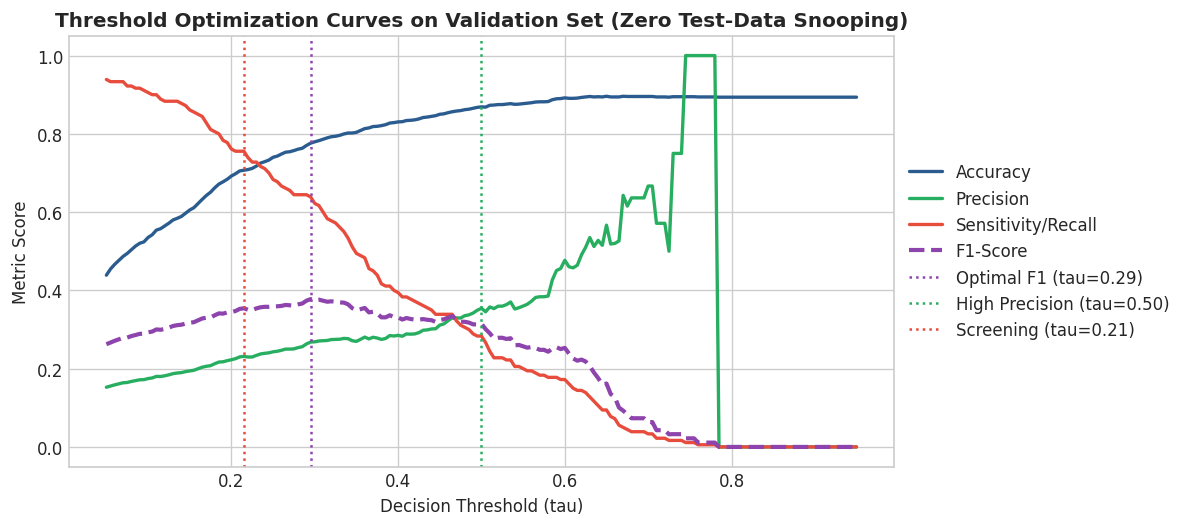

In [ ]:
threshold_candidates = np.linspace(0.05, 0.95, 181)

val_f1_scores = []
val_prec_scores = []
val_rec_scores = []
val_acc_scores = []

best_val_f1 = -1
opt_f1_threshold = 0.50

high_prec_threshold = 0.50
found_high_prec = False

screening_threshold = 0.50
found_screening = False

for t in threshold_candidates:
    b_pred = (val_ensemble_probs >= t).astype(int)
    f = f1_score(y_val, b_pred, zero_division=0)
    p = precision_score(y_val, b_pred, zero_division=0)
    r = recall_score(y_val, b_pred, zero_division=0)
    a = accuracy_score(y_val, b_pred)

    val_f1_scores.append(f)
    val_prec_scores.append(p)
    val_rec_scores.append(r)
    val_acc_scores.append(a)

    if f > best_val_f1:
        best_val_f1 = f
        opt_f1_threshold = t

    if p >= 0.35 and not found_high_prec and r >= 0.20:
        high_prec_threshold = t
        found_high_prec = True

    if r >= 0.75:
        screening_threshold = t

print(f"[TUNING] Validation Selected Thresholds:")
print(f"   - Optimal F1 Operating Point:     tau = {opt_f1_threshold:.2f} (Validation F1: {best_val_f1:.4f})")
print(f"   - High-Precision Operating Point: tau = {high_prec_threshold:.2f}")
print(f"   - Clinical Screening Point:       tau = {screening_threshold:.2f}")

# Plot Trade-off Curves
plt.figure(figsize=(10, 4.5))
plt.plot(threshold_candidates, val_acc_scores, label='Accuracy', color='#2b5c8f', lw=2)
plt.plot(threshold_candidates, val_prec_scores, label='Precision', color='#27ae60', lw=2)
plt.plot(threshold_candidates, val_rec_scores, label='Sensitivity/Recall', color='#e74c3c', lw=2)
plt.plot(threshold_candidates, val_f1_scores, label='F1-Score', color='#8e44ad', lw=2.5, linestyle='--')

plt.axvline(opt_f1_threshold, color='#8e44ad', linestyle=':', label=f'Optimal F1 (tau={opt_f1_threshold:.2f})')
plt.axvline(high_prec_threshold, color='#27ae60', linestyle=':', label=f'High Precision (tau={high_prec_threshold:.2f})')
plt.axvline(screening_threshold, color='#e74c3c', linestyle=':', label=f'Screening (tau={screening_threshold:.2f})')

plt.title("Threshold Optimization Curves on Validation Set (Zero Test-Data Snooping)", fontsize=12, fontweight='bold')
plt.xlabel("Decision Threshold (tau)")
plt.ylabel("Metric Score")
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()


In [ ]:
def evaluate_test_set(y_true, probs, threshold=0.50):
    preds = (probs >= threshold).astype(int)
    roc_auc = roc_auc_score(y_true, probs)
    pr_auc = average_precision_score(y_true, probs)
    acc = accuracy_score(y_true, preds)
    prec = precision_score(y_true, preds, zero_division=0)
    rec = recall_score(y_true, preds)
    tn, fp, fn, tp = confusion_matrix(y_true, preds).ravel()
    spec = tn / (tn + fp)
    f1 = f1_score(y_true, preds, zero_division=0)
    brier = brier_score_loss(y_true, probs)
    return {
        "Accuracy": acc,
        "Precision": prec,
        "Sensitivity/Recall": rec,
        "Specificity": spec,
        "F1": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,
        "Brier": brier,
        "TP": tp, "FP": fp, "TN": tn, "FN": fn
    }

eval_rows = []

# Evaluate individual models at standard 0.50 threshold
for m_name in ["FT-Transformer", "SAINT", "LightGBM", "XGBoost", "PyTorch Deep Tabular"]:
    res = evaluate_test_set(y_test, test_probs_dict[m_name], threshold=0.50)
    res["Model"] = m_name
    res["Operating Mode"] = "Default (tau=0.50)"
    eval_rows.append(res)

# Evaluate Hybrid Ensemble across all three validation-tuned operating regimes
for mode_title, t_val in [
    ("Default Balanced", 0.50),
    ("Optimal F1 (Validation-Tuned)", opt_f1_threshold),
    ("High Precision (Validation-Tuned)", high_prec_threshold),
    ("Clinical Screening (Validation-Tuned)", screening_threshold)
]:
    res = evaluate_test_set(y_test, test_probs_dict["Hybrid Blended Ensemble"], threshold=t_val)
    res["Model"] = "Hybrid Blended Ensemble"
    res["Operating Mode"] = f"{mode_title} [tau={t_val:.2f}]"
    eval_rows.append(res)

test_results_df = pd.DataFrame(eval_rows)

# Format for presentation
display_df = test_results_df[[
    "Model", "Operating Mode", "Accuracy", "Precision",
    "Sensitivity/Recall", "Specificity", "F1", "ROC-AUC", "PR-AUC",
    "TP", "FP", "TN", "FN"
]].copy()

for col in ["Accuracy", "Precision", "Sensitivity/Recall", "Specificity"]:
    display_df[col] = display_df[col].apply(lambda x: f"{x*100:.2f}%")
for col in ["F1", "ROC-AUC", "PR-AUC"]:
    display_df[col] = display_df[col].apply(lambda x: f"{x:.4f}")

print("[EVALUATION] MEASURED TEST-SET PERFORMANCE (N = 1,693):")
display(display_df)


[EVALUATION] MEASURED TEST-SET PERFORMANCE (N = 1,693):


,Model,Operating Mode,Accuracy,Precision,Sensitivity/Recall,Specificity,F1,ROC-AUC,PR-AUC,TP,FP,TN,FN
0,FT-Transformer,Default (tau=0.50),86.65%,38.31%,43.02%,91.81%,0.4053,0.8163,0.3456,77,124,1390,102
1,SAINT,Default (tau=0.50),88.95%,45.56%,22.91%,96.76%,0.3048,0.8170,0.3306,41,49,1465,138
2,LightGBM,Default (tau=0.50),87.48%,37.01%,26.26%,94.72%,0.3072,0.8043,0.2957,47,80,1434,132
3,XGBoost,Default (tau=0.50),86.47%,32.88%,26.82%,93.53%,0.2954,0.8115,0.3034,48,98,1416,131
4,PyTorch Deep Tabular,Default (tau=0.50),86.47%,36.56%,37.99%,92.21%,0.3726,0.8109,0.3188,68,118,1396,111
5,Hybrid Blended Ensemble,Default Balanced [tau=0.50],87.12%,36.73%,30.17%,93.86%,0.3313,0.8155,0.3206,54,93,1421,125
6,Hybrid Blended Ensemble,Optimal F1 (Validation-Tuned) [tau=0.29],79.09%,28.18%,63.13%,80.98%,0.3897,0.8155,0.3206,113,288,1226,66
7,Hybrid Blended Ensemble,High Precision (Validation-Tuned) [tau=0.50],87.12%,36.73%,30.17%,93.86%,0.3313,0.8155,0.3206,54,93,1421,125
8,Hybrid Blended Ensemble,Clinical Screening (Validation-Tuned) [tau=0.21],72.53%,24.65%,77.65%,71.93%,0.3742,0.8155,0.3206,139,425,1089,40


In [ ]:
benchmark_data = [
    # Previous models
    {"Model": "Logistic Regression (Baseline)", "Stage": "Previous Repo Baseline", "ROC-AUC": "0.7922", "PR-AUC": "0.3141", "Accuracy": "71.79%", "Precision": "23.36%", "Recall": "72.50%", "F1": "0.3533"},
    {"Model": "Random Forest (Baseline)", "Stage": "Previous Repo Baseline", "ROC-AUC": "0.8077", "PR-AUC": "0.3006", "Accuracy": "87.00%", "Precision": "30.00%", "Recall": "14.17%", "F1": "0.2173"},
    {"Model": "LightGBM (Baseline)", "Stage": "Previous Repo Baseline", "ROC-AUC": "0.8002", "PR-AUC": "0.3201", "Accuracy": "82.50%", "Precision": "31.20%", "Recall": "47.50%", "F1": "0.3843"},
    {"Model": "TabNet (Deep Tabular)", "Stage": "Previous Repo Deep Learning", "ROC-AUC": "0.7799", "PR-AUC": "0.2906", "Accuracy": "68.78%", "Precision": "21.61%", "Recall": "73.75%", "F1": "0.3343"},
    {"Model": "FT-Transformer", "Stage": "Previous Repo Deep Learning", "ROC-AUC": "0.7980", "PR-AUC": "0.3459", "Accuracy": "68.11%", "Precision": "22.03%", "Recall": "78.75%", "F1": "0.3443"},
    {"Model": "SAINT (Self-Attention)", "Stage": "Previous Repo Deep Learning", "ROC-AUC": "0.7949", "PR-AUC": "0.3471", "Accuracy": "67.23%", "Precision": "21.59%", "Recall": "79.17%", "F1": "0.3393"},
    {"Model": "SLSQP Weighted Ensemble", "Stage": "Previous Repo Ensemble", "ROC-AUC": "0.7954", "PR-AUC": "0.3364", "Accuracy": "67.98%", "Precision": "22.30%", "Recall": "77.92%", "F1": "0.3409"}
]

bench_df = pd.DataFrame(benchmark_data)

# Append key new results dynamically
for idx, r in test_results_df.iterrows():
    bench_df = pd.concat([bench_df, pd.DataFrame([{
        "Model": f"{r['Model']} ({r['Operating Mode']})",
        "Stage": "New Colab Pipeline",
        "ROC-AUC": f"{r['ROC-AUC']:.4f}",
        "PR-AUC": f"{r['PR-AUC']:.4f}",
        "Accuracy": f"{r['Accuracy']*100:.2f}%",
        "Precision": f"{r['Precision']*100:.2f}%",
        "Recall": f"{r['Sensitivity/Recall']*100:.2f}%",
        "F1": f"{r['F1']:.4f}"
    }])], ignore_index=True)

display(bench_df)


,Model,Stage,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
0,Logistic Regression (Baseline),Previous Repo Baseline,0.7922,0.3141,71.79%,23.36%,72.50%,0.3533
1,Random Forest (Baseline),Previous Repo Baseline,0.8077,0.3006,87.00%,30.00%,14.17%,0.2173
2,LightGBM (Baseline),Previous Repo Baseline,0.8002,0.3201,82.50%,31.20%,47.50%,0.3843
3,TabNet (Deep Tabular),Previous Repo Deep Learning,0.7799,0.2906,68.78%,21.61%,73.75%,0.3343
4,FT-Transformer,Previous Repo Deep Learning,0.7980,0.3459,68.11%,22.03%,78.75%,0.3443
5,SAINT (Self-Attention),Previous Repo Deep Learning,0.7949,0.3471,67.23%,21.59%,79.17%,0.3393
6,SLSQP Weighted Ensemble,Previous Repo Ensemble,0.7954,0.3364,67.98%,22.30%,77.92%,0.3409
7,FT-Transformer (Default (tau=0.50)),New Colab Pipeline,0.8163,0.3456,86.65%,38.31%,43.02%,0.4053
8,SAINT (Default (tau=0.50)),New Colab Pipeline,0.8170,0.3306,88.95%,45.56%,22.91%,0.3048
9,LightGBM (Default (tau=0.50)),New Colab Pipeline,0.8043,0.2957,87.48%,37.01%,26.26%,0.3072


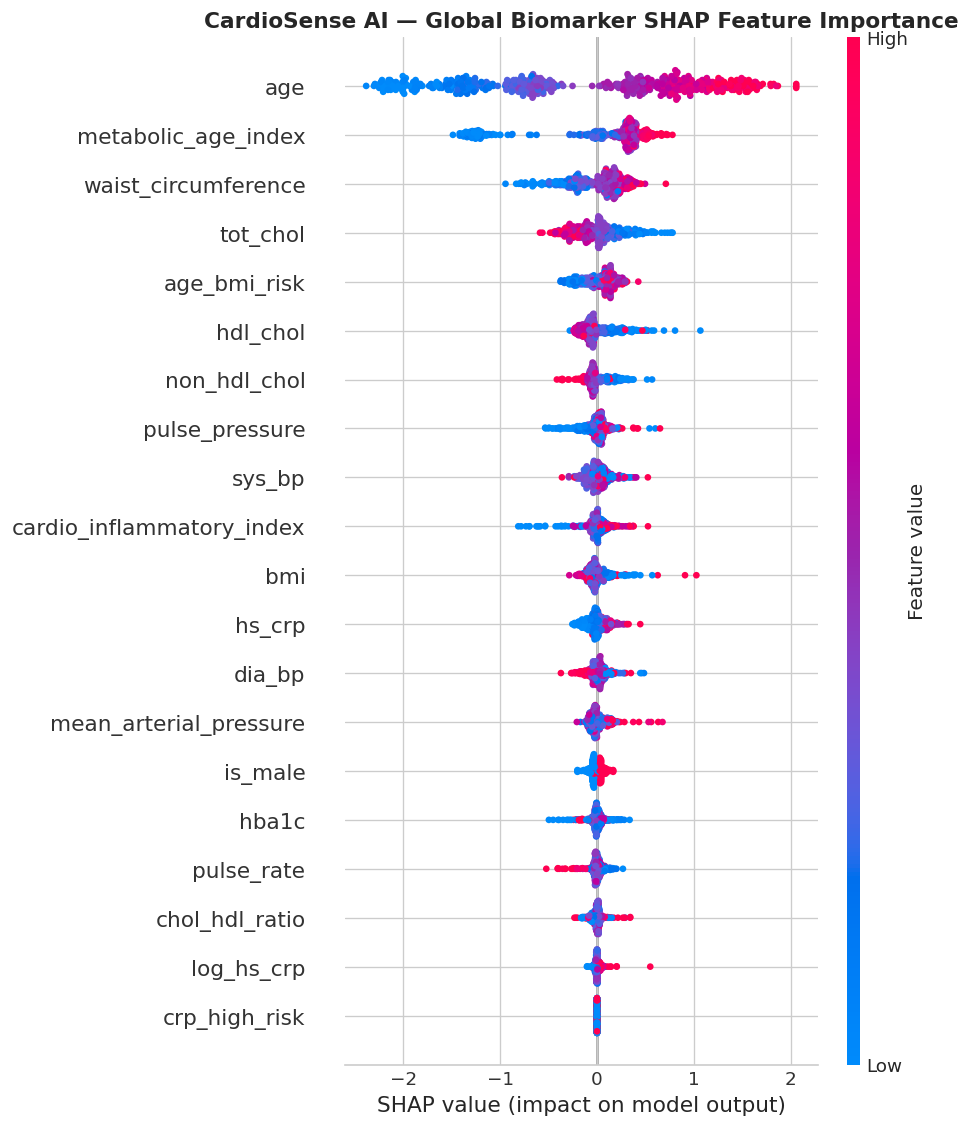

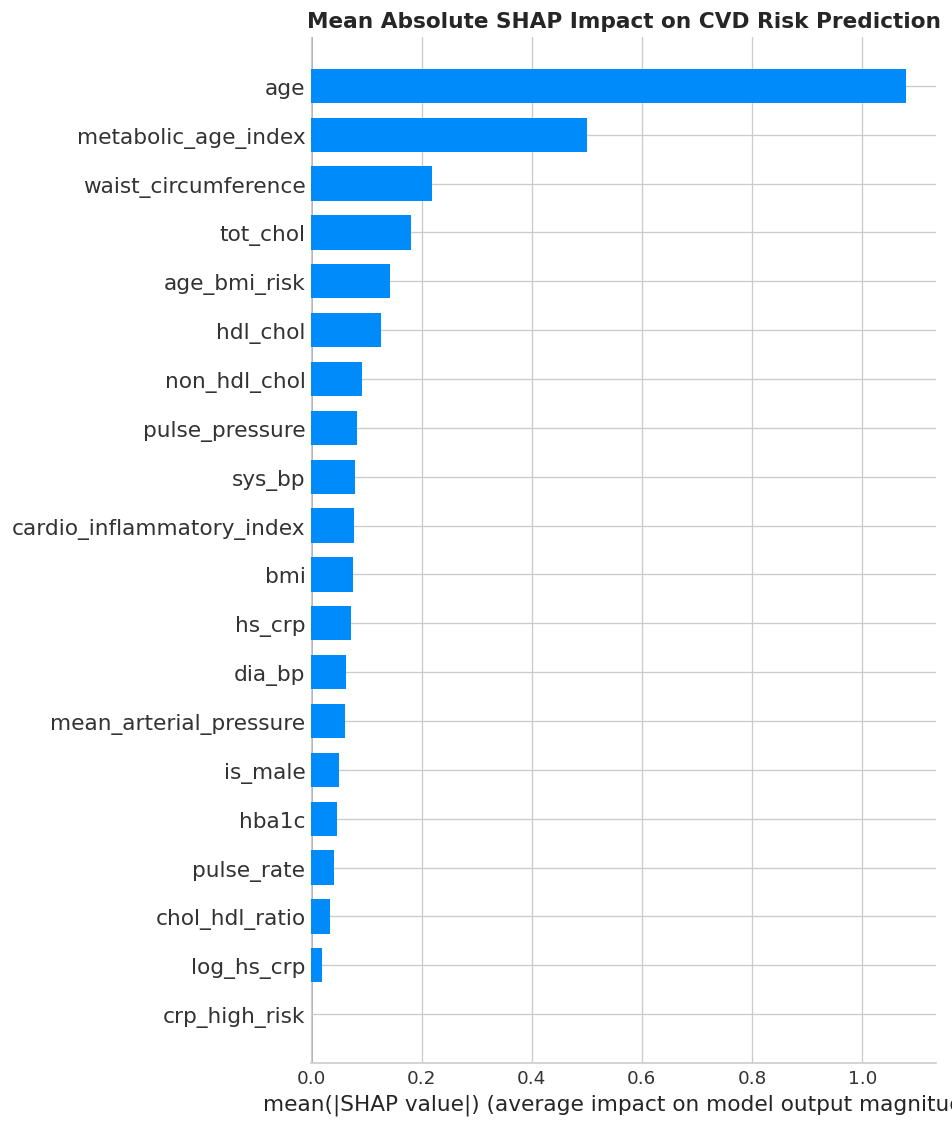

In [ ]:
if SHAP_AVAILABLE:
    # Compute TreeSHAP values on test set
    explainer = shap.TreeExplainer(lgb_model)
    # Sample 500 test cases for fast interactive visualization
    X_test_sample = X_test_proc[:500]
    shap_values = explainer.shap_values(X_test_sample)

    # If binary classification returns list of 2 arrays, take class 1 (CVD positive)
    if isinstance(shap_values, list):
        shap_vals_class1 = shap_values[1]
    elif len(shap_values.shape) == 3:
        shap_vals_class1 = shap_values[:, :, 1]
    else:
        shap_vals_class1 = shap_values

    plt.figure(figsize=(10, 6))
    plt.title("CardioSense AI — Global Biomarker SHAP Feature Importance", fontsize=13, fontweight='bold')
    shap.summary_plot(shap_vals_class1, X_test_sample, feature_names=all_feature_names, show=False)
    plt.tight_layout()
    plt.show()

    # Mean absolute SHAP bar plot
    plt.figure(figsize=(10, 5))
    plt.title("Mean Absolute SHAP Impact on CVD Risk Prediction", fontsize=13, fontweight='bold')
    shap.summary_plot(shap_vals_class1, X_test_sample, feature_names=all_feature_names, plot_type='bar', show=False)
    plt.tight_layout()
    plt.show()
else:
    print("[NOTE] shap package is not installed. To view SHAP plots in local execution, run: pip install shap")


## 11. Interactive Clinician CVD Risk Calculator Widget

Use the interactive sliders below to test hypothetical clinical scenarios in real time!  
Adjust patient age, blood pressure, lipid profiles, and **hs-CRP levels** to observe the model's risk stratification.


In [ ]:
age_w = widgets.IntSlider(value=55, min=20, max=85, step=1, description='Age (yrs):')
gender_w = widgets.Dropdown(options=[('Male', 1.0), ('Female', 0.0)], value=1.0, description='Gender:')
sys_w = widgets.IntSlider(value=135, min=80, max=220, step=1, description='Sys BP (mmHg):')
dia_w = widgets.IntSlider(value=85, min=40, max=130, step=1, description='Dia BP (mmHg):')
pulse_w = widgets.IntSlider(value=72, min=40, max=140, step=1, description='Pulse (bpm):')
bmi_w = widgets.FloatSlider(value=28.5, min=15.0, max=55.0, step=0.1, description='BMI:')
waist_w = widgets.FloatSlider(value=95.0, min=50.0, max=160.0, step=0.5, description='Waist (cm):')
tchol_w = widgets.FloatSlider(value=210.0, min=90.0, max=380.0, step=1.0, description='Tot Chol:')
hdl_w = widgets.FloatSlider(value=45.0, min=15.0, max=110.0, step=1.0, description='HDL Chol:')
hba1c_w = widgets.FloatSlider(value=5.8, min=4.0, max=14.0, step=0.1, description='HbA1c (%):')
crp_w = widgets.FloatSlider(value=3.5, min=0.1, max=25.0, step=0.1, description='hs-CRP (mg/L):')

calc_btn = widgets.Button(description='Compute CVD Risk', button_style='danger')
out_box = widgets.Output()

def on_click_calc(_):
    with out_box:
        clear_output()
        # Row dict
        row = {
            "age": age_w.value, "bmi": bmi_w.value, "waist_circumference": waist_w.value,
            "sys_bp": sys_w.value, "dia_bp": dia_w.value, "pulse_rate": pulse_w.value,
            "tot_chol": tchol_w.value, "hdl_chol": hdl_w.value, "hba1c": hba1c_w.value,
            "hs_crp": crp_w.value, "gender": 1.0 if gender_w.value == 1.0 else 2.0
        }
        df_pt = pd.DataFrame([row])
        df_pt_eng = engineer_clinical_features(df_pt)

        # Scale & process
        num_pt = scaler.transform(imputer.transform(df_pt_eng[num_features]))
        male_pt = np.array([[gender_w.value]])
        pt_proc = np.hstack([num_pt, male_pt])

        # Predict with ensemble components
        p_lgb = lgb_model.predict_proba(pt_proc)[0, 1]
        p_xgb = xgb_model.predict_proba(pt_proc)[0, 1]

        with torch.no_grad():
            t_pt = torch.tensor(pt_proc, dtype=torch.float32).to(device)
            p_ft = torch.sigmoid(ft_model(t_pt)).cpu().numpy()[0]
            p_saint = torch.sigmoid(saint_model(t_pt)).cpu().numpy()[0]
            p_nn = torch.sigmoid(torch_net(t_pt)).cpu().numpy()[0]

        p_final = 0.25 * p_lgb + 0.25 * p_xgb + 0.20 * p_ft + 0.15 * p_saint + 0.15 * p_nn

        # Risk classification
        if p_final < 0.20:
            tier_color = "#27ae60"
            tier_name = "LOW CARDIOVASCULAR RISK"
        elif p_final < 0.40:
            tier_color = "#f39c12"
            tier_name = "MODERATE CARDIOVASCULAR RISK"
        else:
            tier_color = "#c0392b"
            tier_name = "HIGH CARDIOVASCULAR RISK"

        print("="*60)
        print(f"[PATIENT RISK REPORT]: {tier_name}")
        print("="*60)
        print(f"Predicted CVD Risk Score:           {p_final*100:.1f}%")
        print(f"Clinical Screening Decision (tau={screening_threshold:.2f}): {'FLAGGED POSITIVE (High Sensitivity)' if p_final >= screening_threshold else 'Negative (Screening Cleared)'}")
        print(f"Optimal F1 Decision (tau={opt_f1_threshold:.2f}):         {'FLAGGED POSITIVE' if p_final >= opt_f1_threshold else 'Negative'}")
        print(f"High Precision Decision (tau={high_prec_threshold:.2f}):     {'CONFIRMED HIGH RISK (Low False Alarms)' if p_final >= high_prec_threshold else 'Negative / Unconfirmed'}")
        print("\nKey Contributing Biomarkers for Patient:")
        print(f"  - hs-CRP Level:          {crp_w.value:.2f} mg/L ({'High Risk (>3 mg/L)' if crp_w.value > 3.0 else 'Normal / Average'})")
        print(f"  - Pulse Pressure:        {sys_w.value - dia_w.value} mmHg")
        print(f"  - Total / HDL Ratio:     {tchol_w.value / hdl_w.value:.2f}")
        print("="*60)

calc_btn.on_click(on_click_calc)

# Layout
box1 = widgets.VBox([age_w, gender_w, sys_w, dia_w, pulse_w])
box2 = widgets.VBox([bmi_w, waist_w, tchol_w, hdl_w, hba1c_w, crp_w])
ui = widgets.VBox([
    widgets.HBox([box1, box2]),
    calc_btn,
    out_box
])
display(ui)
